# 8b. Extension of notebook 8: what if the target real rate is negative?

This notebook **adds** to notebook `8. empirical_claims.ipynb` and replaces nothing in it. The solver, the model inputs and the helper functions are copied verbatim from notebook 8. The one difference is that the $\rho$ bracket search may start below $\rho=r^*$ when the target is negative; $\rho$ must stay positive and above $r^*$.

**Motivation.**
- At the thesis $\rho=0.05$, the 4-state model clears at $r^*=-0.76\%$.
- Notebook 8 found that Argentina's 50-year ex-post real rate is negative: median $-5.1\%$; 1993–2025 median $-3.6\%$.
- So, should the target be a negative real rate? This notebook repeats the notebook-8 test, calibrating $\rho$ so that $r^*$ equals the target, for a range of targets from $+2\%$ down to the data medians.

**What is judged.** For each target:
1. **The calibrated parameter**, $\rho$ (or $\beta=e^{-\rho}$): is it inside the range used in the literature?
2. **Untargeted predictions**, which were not used in the calibration: borrower share, mass at the borrowing limit, the informal/formal consumption ratio, and debt relative to income. These are the moments that could later be compared with household data such as ENGHo or Global Findex.

In [1]:
import os, math, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.sparse import spdiags, eye, bmat, kron, csc_matrix
from scipy.sparse.linalg import spsolve

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "axes.grid": True,
                     "grid.color": "#e8e8e8", "legend.frameon": False})
MODEL_DATA = "data"                                    # repo data folder (lambdas, incomes)
DATA_DIR = os.path.join(MODEL_DATA, "interest_rates")  # interest-rate inputs and results of this notebook
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
R_TARGET = 0.02   # needed only as a default argument of the functions copied from notebook 8

In [3]:
I_GRID, AMIN, AMAX = 800, -0.099, 5.0
a = np.linspace(AMIN, AMAX, I_GRID)
da = (AMAX - AMIN) / (I_GRID - 1)

def solve_given_r(r, rho, m, V_init=None, Delta=1000.0, maxit=400):
    z, gamma, tau, theta = m["z"], m["gamma"], m["tau"], m["theta"]
    I, N = len(a), len(z)
    zat = (1 - tau) * z
    zz = np.ones((I, 1)) * zat[None, :]
    aa = np.repeat(a[:, None], N, axis=1)
    R = r + theta[None, :] * (a < 0)[:, None]
    Lam = np.array(m["Lambda"], float).copy()
    np.fill_diagonal(Lam, 0.0); np.fill_diagonal(Lam, -Lam.sum(1))       # enforce row sums = 0
    Asw = kron(csc_matrix(Lam), eye(I), format="csc")
    if V_init is None:
        V = np.maximum(zz + r * aa, 1e-12) ** (1 - gamma) / ((1 - gamma) * rho)
    else:
        V = V_init.copy()
    dVf = np.zeros((I, N)); dVb = np.zeros((I, N)); converged = False
    for it in range(maxit):
        dVf[:-1] = (V[1:] - V[:-1]) / da
        dVf[-1] = np.maximum(zat + r * AMAX, 1e-12) ** (-gamma)
        dVb[1:] = (V[1:] - V[:-1]) / da
        dVb[0] = np.maximum(zat + (r + theta) * AMIN, 1e-12) ** (-gamma)
        cf = np.maximum(dVf, 1e-12) ** (-1 / gamma)
        cb = np.maximum(dVb, 1e-12) ** (-1 / gamma)
        ssf = zz + R * aa - cf; ssb = zz + R * aa - cb; c0 = zz + R * aa
        If = (ssf > 1e-14).astype(float); Ib = (ssb < -1e-14).astype(float); I0 = 1 - If - Ib
        c = cf * If + cb * Ib + c0 * I0
        util = np.maximum(c, 1e-12) ** (1 - gamma) / (1 - gamma)
        X = -np.minimum(ssb, 0) / da
        Y = -np.maximum(ssf, 0) / da + np.minimum(ssb, 0) / da
        Zc = np.maximum(ssf, 0) / da
        blocks = [spdiags(Y[:, j], 0, I, I) + spdiags(X[1:, j], -1, I, I)
                  + spdiags(np.hstack(([0.0], Zc[:-1, j])), 1, I, I) for j in range(N)]
        A = bmat([[blocks[i] if i == j else None for j in range(N)] for i in range(N)], format="csc") + Asw
        if np.max(np.abs(np.asarray(A.sum(axis=1)).ravel())) > 1e-7:
            # Same check as notebooks 4/5; here the point is flagged invalid instead of aborting
            return dict(V=V, c=c, g=None, adot=None, S=np.nan, valid=False, iters=it + 1)
        B = (1 / Delta + rho) * eye(N * I, format="csc") - A
        Vn = spsolve(B, util.T.ravel() + V.T.ravel() / Delta).reshape(N, I).T
        diff = np.max(np.abs(Vn - V)); V = Vn
        if diff < 1e-6:
            converged = True; break
    AT = A.T.tolil(); b = np.zeros(N * I); AT[0, :] = 0; AT[0, 0] = 1; b[0] = 1
    g = spsolve(AT.tocsr(), b).reshape(N, I).T
    g /= g.sum() * da
    valid = converged and (g.min() * da > -1e-8)
    return dict(V=V, c=c, g=g, adot=zz + R * aa - c, S=float((g * a[:, None]).sum() * da),
                valid=valid, iters=it + 1)

def find_equilibrium(rho, m, rmin, rmax, r0=0.03, tol_S=1e-5, max_iter=100):
    # Same bisection rule as notebooks 4/5: S>0 -> lower r, S<0 -> raise r
    r, V = r0, None
    for _ in range(max_iter):
        out = solve_given_r(r, rho, m, V_init=V)
        if out["S"] > tol_S:   rmax, r = r, 0.5 * (r + rmin)
        elif out["S"] < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else: return r, out, True
        V = out["V"]
    return r, out, False

In [4]:
def read_generator(fname, order):
    # Read a generator CSV exported by the R scripts and reorder rows/cols by state label
    df = pd.read_csv(os.path.join(MODEL_DATA, fname), index_col=0)
    df.index = df.index.str.strip(); df.columns = df.columns.str.strip()
    return df.loc[order, order].to_numpy(float)

L2_DATA = read_generator("lambda_matrix_2state_datadriven.csv", ["I", "F"])
TOTAL_HAZARD_2S = L2_DATA[0, 1] + L2_DATA[1, 0]        # lam_IF + lam_FI from EPH
print(f"2-state data generator: lam_IF={L2_DATA[0,1]:.6f}, lam_FI={L2_DATA[1,0]:.6f}, total={TOTAL_HAZARD_2S:.6f}")

def lambda_2state(eta, s=TOTAL_HAZARD_2S):
    # row = from, col = to ; states (I, F); stationary informal share = eta (same split as notebook 4)
    return np.array([[0.0, (1 - eta) * s], [eta * s, 0.0]])

ORDER4 = ["IH", "IL", "FH", "FL"]   # model order used in notebook 5
LAMBDA4_ETA42 = read_generator("lambda_matrix_4state_datadriven.csv", ORDER4)       # thesis Table 3
LAMBDA4_ETA20 = read_generator("lambda_matrix_4state_benchmark_eta20.csv", ORDER4)  # thesis Table 2

def model_2state(eta=0.42, gamma_I=0.30, tau_F=0.19):
    return dict(name="2-state", labels=["I", "F"], informal=[0], formal=[1],
                z=np.array([0.418, 1.0]), gamma=np.array([gamma_I, 0.15]),
                tau=np.array([0.0, tau_F]), theta=np.array([0.02, 0.0]), Lambda=lambda_2state(eta))

def model_4state(eta=0.42, tau_FH=0.19, tau_FL=0.05):
    L = {0.42: LAMBDA4_ETA42, 0.20: LAMBDA4_ETA20}[eta]
    return dict(name="4-state", labels=["IH", "IL", "FH", "FL"], informal=[0, 1], formal=[2, 3],
                z=np.array([0.82979213, 0.219700297, 1.0, 0.321119145]),
                gamma=np.array([0.30, 0.30, 0.15, 0.15]),
                tau=np.array([0.0, 0.0, tau_FH, tau_FL]), theta=np.array([0.02, 0.02, 0.0, 0.0]), Lambda=L)

def stationary(L):
    L = np.array(L, float).copy(); np.fill_diagonal(L, 0); np.fill_diagonal(L, -L.sum(1))
    w, v = np.linalg.eig(L.T); p = np.real(v[:, np.argmin(np.abs(w))]); return p / p.sum()

for eta in (0.20, 0.42):
    p = stationary(model_4state(eta)["Lambda"])
    print(f"4-state eta={eta}: stationary (IH,IL,FH,FL) = {np.round(p,4)}, informal = {p[:2].sum():.4f}, "
          f"phi = IH/(IH+IL) = {p[0]/p[:2].sum():.3f}")

2-state data generator: lam_IF=0.684364, lam_FI=0.229618, total=0.913981
4-state eta=0.2: stationary (IH,IL,FH,FL) = [0.0368 0.1632 0.556  0.244 ], informal = 0.2000, phi = IH/(IH+IL) = 0.184
4-state eta=0.42: stationary (IH,IL,FH,FL) = [0.0772 0.3428 0.4031 0.1769], informal = 0.4200, phi = IH/(IH+IL) = 0.184


In [5]:
def bracket_rho(m, r_target, step=0.005, rho_max=0.30):
    # Walk up from just above r_target: lo = last VALID rho with S>0, hi = first rho with S<0
    lo, rho = None, r_target + step
    while rho <= rho_max:
        out = solve_given_r(r_target, rho, m)
        if out["valid"] and out["S"] > 0: lo = rho
        elif out["valid"] and out["S"] < 0:
            assert lo is not None, "no valid rho with S>0 below the root"
            return lo, rho
        rho += step
    raise RuntimeError("root not bracketed")

def calibrate_rho(m, r_target=R_TARGET, tol=1e-7, max_iter=60):
    lo, hi = bracket_rho(m, r_target)
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi); out = solve_given_r(r_target, mid, m)
        assert out["valid"], f"invalid solve at rho={mid}"
        if out["S"] > 0: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi)

In [6]:
def moments(m, out, r):
    g, c, adot = out["g"], out["c"], out["adot"]
    mass = g.sum(0) * da
    inf, frm = m["informal"], m["formal"]
    row = {"r* %": 100 * r,
           "borrowers mass (a<0)": (g[a < 0].sum()) * da,
           "mass at borrowing limit (first grid pt)": g[0].sum() * da,
           "informal: share borrowing": g[a < 0][:, inf].sum() * da / mass[inf].sum(),
           "formal: share borrowing": g[a < 0][:, frm].sum() * da / mass[frm].sum(),
           "informal mean wealth": (g[:, inf] * a[:, None]).sum() * da / mass[inf].sum(),
           "formal mean wealth": (g[:, frm] * a[:, None]).sum() * da / mass[frm].sum(),
           "informal mean consumption": (g[:, inf] * c[:, inf]).sum() * da / mass[inf].sum(),
           "formal mean consumption": (g[:, frm] * c[:, frm]).sum() * da / mass[frm].sum(),
           "gross debt / mean after-tax income": (g * np.maximum(-a, 0)[:, None]).sum() * da
                                                 / (mass * (1 - m["tau"]) * m["z"]).sum()}
    for j, lab in enumerate(m["labels"]):
        row[f"[{lab}] mass"] = mass[j]
        row[f"[{lab}] mean wealth"] = (g[:, j] * a).sum() * da / mass[j]
        row[f"[{lab}] share borrowing"] = g[a < 0, j].sum() * da / mass[j]
    return row

## Step 0. A numerical fix for $r \le 0$ (initial guess only)

The solver in notebooks 4, 5 and 8 starts the value-function iteration from $V_0=u(\tilde y + r a)/\rho$.
- For $r\le 0$ this guess is flat or decreasing in $a$. The first upwind step then breaks the generator, and the solve fails at iteration 1 for **every** $\rho$.
- Notebook 8 only reached $r^*=-0.76\%$ because its bisection warm-starts from a positive-$r$ solution.
- This is a property of the starting point, not of the economics.

Here the solver is unchanged. We only pass it a different starting point, $V_0=u(\tilde y+\rho a)/\rho$, which is increasing and concave for any $r$. The HJB has a unique fixed point, so the converged solution must not depend on $V_0$. The next cell checks this at $r=2\%$ against the notebook-8 guess.

**Continuation.** At negative $r$, even this guess can fail when $\rho$ is far from a solved point. Two standard remedies are used, and neither changes the fixed point:
1. warm-start each $\rho$ from the last valid solution;
2. if that still fails, retry with a smaller implicit step ($\Delta=50$, up to 3000 iterations).

$S=a_{\min}\approx-0.099$ means the whole population sits at the borrowing limit. That is a genuine corner of the model, not a failed solve.

In [7]:
def guess_V(m, rho):
    zat = (1 - m["tau"]) * m["z"]
    c0 = np.maximum(zat[None, :] + rho * a[:, None], 1e-12)
    return c0 ** (1 - m["gamma"]) / ((1 - m["gamma"]) * rho)

def solve_r(r, rho, m, V_init=None):
    return solve_given_r(r, rho, m, V_init=guess_V(m, rho) if V_init is None else V_init)

def solve_cont(r, rho, m, V_init=None):
    # solve with warm start; if invalid, retry with a smaller implicit step (same fixed point)
    out = solve_r(r, rho, m, V_init=V_init)
    if not out["valid"]:
        out = solve_given_r(r, rho, m, V_init=guess_V(m, rho) if V_init is None else V_init,
                            Delta=50.0, maxit=3000)
    return out

def find_equilibrium_g(rho, m, rmin, rmax, r0, V0=None, tol_S=1e-5, max_iter=100):
    # notebook-8 bisection; only the starting value function and the fallback differ
    r, V = r0, V0
    for _ in range(max_iter):
        out = solve_cont(r, rho, m, V_init=V)
        if not out["valid"]: return r, out, False
        if out["S"] > tol_S:   rmax, r = r, 0.5 * (r + rmin)
        elif out["S"] < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else: return r, out, True
        V = out["V"]
    return r, out, False

chk = []
for mk in (model_2state, model_4state):
    m = mk(0.42)
    o_old = solve_given_r(0.02, 0.05, m); o_new = solve_r(0.02, 0.05, m)
    chk.append({"model": m["name"], "S old guess": o_old["S"], "S new guess": o_new["S"],
                "max |V_old - V_new|": np.abs(o_old["V"] - o_new["V"]).max(),
                "valid at r=0, rho=0.05 (old guess)": solve_given_r(0.0, 0.05, m)["valid"],
                "valid at r=0, rho=0.05 (new guess)": solve_r(0.0, 0.05, m)["valid"]})
pd.DataFrame(chk)

,model,S old guess,S new guess,max |V_old - V_new|,"valid at r=0, rho=0.05 (old guess)","valid at r=0, rho=0.05 (new guess)"
0,2-state,0.023759,0.023759,5.392309e-11,False,True
1,4-state,0.158760,0.158760,3.023413e-10,False,True


## Step 1. Targets

The targets include 2% (notebook 8), zero, and negative values. Two of them are data moments computed in notebook 8 from `data/interest_rates/argentina_real_rate_summary.csv`: the 1993–2025 median and the 1976–2025 median of the ex-post real short-term rate.

In [8]:
summary = pd.read_csv(os.path.join(DATA_DIR, "argentina_real_rate_summary.csv"))
med_50y = summary.query("series == 'short-term rate' and window == '1976-2025'")["real median %"].item() / 100
med_93 = summary.query("series == 'short-term rate' and window == '1993-2025'")["real median %"].item() / 100
TARGETS = {"+2% (notebook 8)": 0.02, "0%": 0.0, "-1%": -0.01, "-2%": -0.02,
           f"1993-2025 median ({100*med_93:.2f}%)": med_93, f"1976-2025 median ({100*med_50y:.2f}%)": med_50y}
TARGETS

{'+2% (notebook 8)': 0.02,
 '0%': 0.0,
 '-1%': -0.01,
 '-2%': -0.02,
 '1993-2025 median (-3.56%)': -0.035623287852616814,
 '1976-2025 median (-5.12%)': -0.05122231674678767}

## Step 2. Calibrate $\rho$ to each target in each model

- `bracket_rho_pos` is notebook 8's `bracket_rho`, except that the walk starts at $\max(r^*,0)$ plus a step, because $\rho$ must be positive.
- A point counts as invalid, exactly as in notebook 8, when wealth runs into $a_{\max}$ (HJB not converged or improper generator). If no valid $\rho$ hits the target, the table reports it rather than guessing.
- Each calibration is then verified by re-solving the full equilibrium.
- Every solve uses the Step 0 initial guess and continuation.

In [9]:
def bracket_rho_pos(m, r_target, step=0.0025, rho_max=0.30):
    # Walk rho upward with continuation; lo = last valid rho with S>0, hi = first valid rho with S<0
    lo, V_lo, V, rho = None, None, None, max(r_target, 0.0) + step
    while rho <= rho_max:
        out = solve_cont(r_target, rho, m, V_init=V)
        if out["valid"]:
            V = out["V"]
            if out["S"] > 0: lo, V_lo = rho, V
            elif out["S"] < 0: return lo, rho, V_lo
        rho += step
    return lo, None, V_lo

def calibrate_rho_pos(m, r_target, tol=1e-7, max_iter=60):
    lo, hi, V = bracket_rho_pos(m, r_target)
    if hi is None: return np.nan, "not bracketed", None
    if lo is None:
        return np.nan, f"S<0 already at the smallest rho tried ({hi:.4f}): no rho>0 reaches this r*", None
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi); out = solve_cont(r_target, mid, m, V_init=V)
        if not out["valid"]: return np.nan, f"invalid solve at rho={mid:.4f}", None
        V = out["V"]
        if out["S"] > 0: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi), "ok", V

rows, sols = [], {}
for lab, rt in TARGETS.items():
    for mk in (model_2state, model_4state):
        m = mk(0.42)
        rho, status, V_cal = calibrate_rho_pos(m, rt)
        row = {"target": lab, "r* target %": 100 * rt, "model": m["name"], "rho": rho, "status": status}
        if status == "ok":
            r, out, ok = find_equilibrium_g(rho, m, rmin=-0.15, rmax=0.10, r0=rt, V0=V_cal)
            row.update({"annual beta": np.exp(-rho), "quarterly beta": np.exp(-rho / 4),
                        "verified r* %": 100 * r, "cleared": ok and out["valid"]})
            sols[(lab, m["name"])] = (m, out, r)
        rows.append(row)
tab_neg = pd.DataFrame(rows)
tab_neg.to_csv(os.path.join(DATA_DIR, "calibration_rho_negative_targets.csv"), index=False)
tab_neg.round(4)

,target,r* target %,model,rho,status,annual beta,quarterly beta,verified r* %,cleared
0,+2% (notebook 8),2.0000,2-state,0.0542,ok,0.9473,0.9866,2.0000,True
1,+2% (notebook 8),2.0000,4-state,0.0780,ok,0.9250,0.9807,2.0000,True
2,0%,0.0000,2-state,0.0340,ok,0.9665,0.9915,0.0000,True
3,0%,0.0000,4-state,0.0577,ok,0.9439,0.9857,0.0000,True
4,-1%,-1.0000,2-state,0.0240,ok,0.9763,0.9940,-1.0000,True
5,-1%,-1.0000,4-state,0.0476,ok,0.9535,0.9882,-1.0000,True
6,-2%,-2.0000,2-state,0.0139,ok,0.9862,0.9965,-2.0000,True
7,-2%,-2.0000,4-state,0.0375,ok,0.9632,0.9907,-2.0000,True
8,1993-2025 median (-3.56%),-3.5623,2-state,NaN,S<0 already at the smallest rho tried (0.0025)...,NaN,NaN,NaN,NaN
9,1993-2025 median (-3.56%),-3.5623,4-state,0.0217,ok,0.9785,0.9946,-3.5623,True


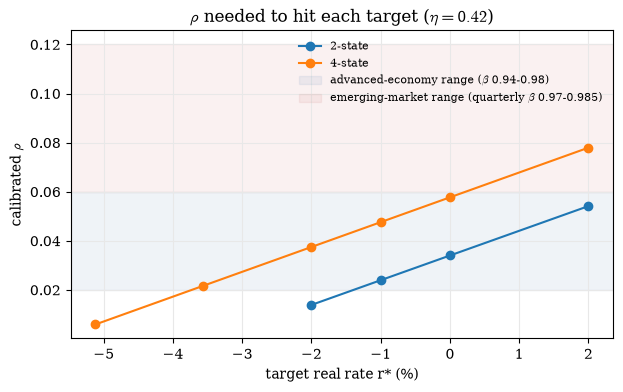

model,2-state,4-state,rho_4s - rho_2s,2-state: rho - r*,4-state: rho - r*
r* target %,,,,,
2.000000,0.0542,0.0780,0.0238,0.0342,0.0580
0.000000,0.0340,0.0577,0.0237,0.0340,0.0577
-1.000000,0.0240,0.0476,0.0237,0.0340,0.0576
-2.000000,0.0139,0.0375,0.0236,0.0339,0.0575
-3.562329,NaN,0.0217,NaN,NaN,0.0573
-5.122232,NaN,0.0059,NaN,NaN,0.0571


In [10]:
piv = tab_neg.pivot(index="r* target %", columns="model", values="rho").sort_index(ascending=False)
piv["rho_4s - rho_2s"] = piv["4-state"] - piv["2-state"]
for mname in ("2-state", "4-state"):
    piv[f"{mname}: rho - r*"] = piv[mname] - piv.index / 100   # impatience gap
piv.to_csv(os.path.join(DATA_DIR, "rho_and_gap_by_target.csv"))
fig, ax = plt.subplots(figsize=(7, 4))
for mname in ("2-state", "4-state"):
    ax.plot(piv.index, piv[mname], "o-", label=mname)
ax.axhspan(0.02, 0.06, color="#3b6ea5", alpha=0.08, label=r"advanced-economy range ($\beta$ 0.94-0.98)")
ax.axhspan(0.06, 0.12, color="#c0504d", alpha=0.08, label=r"emerging-market range (quarterly $\beta$ 0.97-0.985)")
ax.set_xlabel("target real rate r* (%)"); ax.set_ylabel(r"calibrated $\rho$"); ax.legend(fontsize=8)
ax.set_title(r"$\rho$ needed to hit each target ($\eta=0.42$)"); plt.show()
piv.round(4)

## Step 3. Untargeted predictions at each calibration

None of these moments were targeted. They are what each model predicts once it has been forced to match the same $r^*$. They are the natural place to compare with household data later; no such data are used here.

In [11]:
pred = []
for (lab, mname), (m, out, r) in sols.items():
    mo = moments(m, out, r)
    pred.append({"target": lab, "model": mname, "r* %": 100 * r,
                 "borrowers mass": mo["borrowers mass (a<0)"],
                 "mass at borrowing limit": mo["mass at borrowing limit (first grid pt)"],
                 "informal share borrowing": mo["informal: share borrowing"],
                 "formal share borrowing": mo["formal: share borrowing"],
                 "c_informal / c_formal": mo["informal mean consumption"] / mo["formal mean consumption"],
                 "gross debt / income": mo["gross debt / mean after-tax income"]})
pred = pd.DataFrame(pred).sort_values(["model", "r* %"], ascending=[True, False])
pred.to_csv(os.path.join(DATA_DIR, "untargeted_moments_by_target.csv"), index=False)
pred.round(4)

,target,model,r* %,borrowers mass,mass at borrowing limit,informal share borrowing,formal share borrowing,c_informal / c_formal,gross debt / income
0,+2% (notebook 8),2-state,2.0000,0.4911,0.2340,0.8605,0.2235,0.6196,0.0557
2,0%,2-state,0.0000,0.4909,0.2345,0.8613,0.2226,0.6223,0.0557
4,-1%,2-state,-1.0000,0.4907,0.2348,0.8616,0.2222,0.6237,0.0557
6,-2%,2-state,-2.0000,0.4906,0.2350,0.8620,0.2217,0.6251,0.0557
1,+2% (notebook 8),4-state,2.0000,0.5219,0.2191,0.7584,0.3506,0.5509,0.0714
3,0%,4-state,0.0000,0.5220,0.2199,0.7593,0.3502,0.5531,0.0715
5,-1%,4-state,-1.0000,0.5221,0.2204,0.7597,0.3500,0.5542,0.0716
7,-2%,4-state,-2.0000,0.5221,0.2208,0.7602,0.3498,0.5553,0.0716
8,1993-2025 median (-3.56%),4-state,-3.5623,0.5222,0.2214,0.7609,0.3494,0.5570,0.0717
9,1976-2025 median (-5.12%),4-state,-5.1222,0.5223,0.2220,0.7616,0.3491,0.5588,0.0718


## Step 4. Reading the results

**1. What is pinned down is the impatience gap $\rho - r^*$, not $\rho$ itself.**
- Across all targets the gap is almost constant: about $0.034$ in the 2-state model and $0.058$ in the 4-state model.
- The untargeted predictions in Step 3 barely change with the target. Moving $r^*$ and $\rho$ together leaves household behaviour almost unchanged.

**2. For positive or mildly negative targets ($+2\%$ to $-2\%$), both models calibrate with positive $\rho$.**
- The 2-state $\rho$ falls toward very patient values: $\rho=0.014$ ($\beta=0.986$ annual) at $-2\%$.
- The 4-state $\rho$ stays in an ordinary range: $0.038$ to $0.078$.

**3. At the data medians, only the 4-state model can be calibrated.**
- The 1993–2025 median is $-3.6\%$; the 1976–2025 median is $-5.1\%$.
- With a positive discount rate, the 2-state model cannot generate $r^*=-3.6\%$ or $-5.1\%$. Even at $\rho=0.0025$, households already hold too few bonds. Extrapolating its gap, it would need $\rho\approx -0.2\%$ and $-1.7\%$: households valuing the future more than the present, which is not a standard parameter.
- The 4-state model reaches $-3.6\%$ with $\rho=0.022$ ($\beta=0.978$), a textbook value. It reaches $-5.1\%$ with $\rho=0.006$ ($\beta=0.994$), very patient but positive.

**4. So which model has the "strange" parameter depends on the target.**
- **Positive targets:** neither model is strange; the 4-state needs more impatience.
- **The negative ex-post data medians:** the 2-state model needs a negative discount rate, while the 4-state does not.
- The reason is that the 4-state model has more precautionary saving: at the same $\rho$ it wants to hold more bonds, so only a low or negative $r^*$ clears the market. That is the feature that lets it match a negative real rate.

**5. Caveat that decides whether point 3 matters.** It holds only if a negative ex-post real rate is the right counterpart to the model's $r^*$.
- The model's $r^*$ is the equilibrium return on the only risk-free saving vehicle, traded among households. Argentina's negative ex-post peso rates mostly reflect surprise inflation, rate caps and financial repression.
- Argentine households save largely in dollars and real estate, outside peso deposits. A target based on dollar returns would be closer to $0$–$1\%$.
- Points 1–2 apply to that range.

In [12]:
print(piv.round(4).to_string())
print()
print(pred.round(3).to_string(index=False))

model        2-state  4-state  rho_4s - rho_2s  2-state: rho - r*  4-state: rho - r*
r* target %                                                                         
 2.000000     0.0542   0.0780           0.0238             0.0342             0.0580
 0.000000     0.0340   0.0577           0.0237             0.0340             0.0577
-1.000000     0.0240   0.0476           0.0237             0.0340             0.0576
-2.000000     0.0139   0.0375           0.0236             0.0339             0.0575
-3.562329        NaN   0.0217              NaN                NaN             0.0573
-5.122232        NaN   0.0059              NaN                NaN             0.0571

                   target   model   r* %  borrowers mass  mass at borrowing limit  informal share borrowing  formal share borrowing  c_informal / c_formal  gross debt / income
         +2% (notebook 8) 2-state  2.000           0.491                    0.234                     0.861                   0.224            